Mission 4 - Predicting House Price with Multiple Linear Regression
Introduction In this mission, you will be working with a real estate dataset to perform Exploratory Data Analysis (EDA) and create a Multiple Linear Regression (MLR) model to predict the Price of a house based on various features such as Square Feet, Number of Bedrooms, Number of Bathrooms, and other factors.

The dataset includes the following columns:

Square_Feet: The total area of the house in square feet.

Num_Bedrooms: The number of bedrooms in the house.

Num_Bathrooms: The number of bathrooms in the house.

Num_Floors: The number of floors in the house.

Garage_Size: The size of the garage.

Location_Score: A score representing the desirability of the location.

Distance_to_Center: The distance (in km) to the city center.

Price: The price of the house (target variable).

Step 1. Loading and Understanding the Data


Task 1.1. The data is stored in Azure Blob Storage. To connect to Azure Blob Storage, we will use a connection string that contains authentication details such as the account name and account key. See the credentials below.

Task 1.2. Load the dataset into a Pandas DataFrame from the CSV file stored in Blob Storage. Name the dataframe as df_house_price

Task 1.3. Display the first few rows

Task 1.4. Check the data types and null values

In [1]:
!pip install azure-storage-blob pandas

In [2]:
# Task 1.1., 1.2. , 1.3.

# Treats text in memory like a file (for Pandas)
from io import StringIO

# Loads the library for handling data tables
import pandas as pd

# Loads Azure tools to connect to cloud storage
from azure.storage.blob import BlobServiceClient

# Define Azure Storage credentials, container name, and file name
connect_str = "DefaultEndpointsProtocol=https;AccountName=level5data;AccountKey=cWgxWhPELQdrW0sIgA/eXM8/k9+xdaELukN8sg5imfhm4wVIJQFmypEph/Ppy500v41mYT+iCBbC+AStsfHbAQ==;EndpointSuffix=core.windows.net"
container_name = "businesscases"
blob_name = "house_sales_prediction.csv"

# Authenticate and connect to the Azure Blob Service
blob_service_client = BlobServiceClient.from_connection_string(connect_str)

# Navigate to the specific container and file (blob)
container_client = blob_service_client.get_container_client(container_name)
blob_client = container_client.get_blob_client(blob_name)

# Download the blob data and decode it into a UTF-8 string
blob_data = blob_client.download_blob()
csv_content = blob_data.readall().decode("utf-8")

# Wrap the string in StringIO (so pandas treats it like a file) and read into a DataFrame
df_house_price = pd.read_csv(StringIO(csv_content))

# Preview the first 5 rows of the house price dataset
df_house_price.head()

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Garage_Size,Location_Score,Distance_to_Center,Price
0,143.635030,1,3,3,48,8.297631,5.935734,602134.8167
1,287.678577,1,2,1,37,6.061466,10.827392,591425.1354
2,232.998485,1,3,2,14,2.911442,6.904599,464478.6969
3,199.664621,5,2,2,17,2.070949,8.284019,583105.6560
4,89.004660,4,3,3,34,1.523278,14.648277,619879.1425


In [4]:
# Task 1.4. Check the data types and null values.

df_house_price.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Square_Feet         500 non-null    float64
 1   Num_Bedrooms        500 non-null    int64  
 2   Num_Bathrooms       500 non-null    int64  
 3   Num_Floors          500 non-null    int64  
 4   Garage_Size         500 non-null    int64  
 5   Location_Score      500 non-null    float64
 6   Distance_to_Center  500 non-null    float64
 7   Price               500 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 31.4 KB


Step 2. Exploratory Data Analysis (EDA)


Task 2.1. Check summary statistics for the dataset

Task 2.2. Visualise the relationship between Square Feet and Price using a scatter plot

Task 2.3. Visualise the distribution of the Price variable using a histogram

Task 2.4. Compute and visualize the correlation matrix between the features

Task 2.5. Write 1-2 sentences explaining the insights from each visualisation.

In [7]:
# Task 2.1. Check the summary statistics for the dataset

df_house_price.describe()

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Garage_Size,Location_Score,Distance_to_Center,Price
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,174.640428,2.958000,1.976000,1.964000,30.174000,5.164410,10.469641,582209.629531
std,74.672102,1.440968,0.820225,0.802491,11.582575,2.853489,5.588197,122273.390347
min,51.265396,1.000000,1.000000,1.000000,10.000000,0.004428,0.062818,276892.470100
25%,110.319923,2.000000,1.000000,1.000000,20.000000,2.760650,6.066754,503080.344175
50%,178.290937,3.000000,2.000000,2.000000,30.000000,5.206518,10.886066,574724.113350
75%,239.031220,4.000000,3.000000,3.000000,41.000000,7.732933,15.072590,665942.301300
max,298.241199,5.000000,3.000000,3.000000,49.000000,9.995439,19.927966,960678.274300


In [5]:
# Closest to the city center

df_house_price[df_house_price["Distance_to_Center"].round(6) == 0.062818]

# or

df_house_price[df_house_price["Distance_to_Center"].between(0.06, 0.07)]

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Garage_Size,Location_Score,Distance_to_Center,Price
335,60.182201,5,1,2,32,1.439419,0.062818,483429.605


In [6]:
# Farthest to the city center

df_house_price[df_house_price["Distance_to_Center"].round(6) == 19.927966]

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Garage_Size,Location_Score,Distance_to_Center,Price
446,296.500266,1,3,2,22,2.100293,19.927966,659323.2209


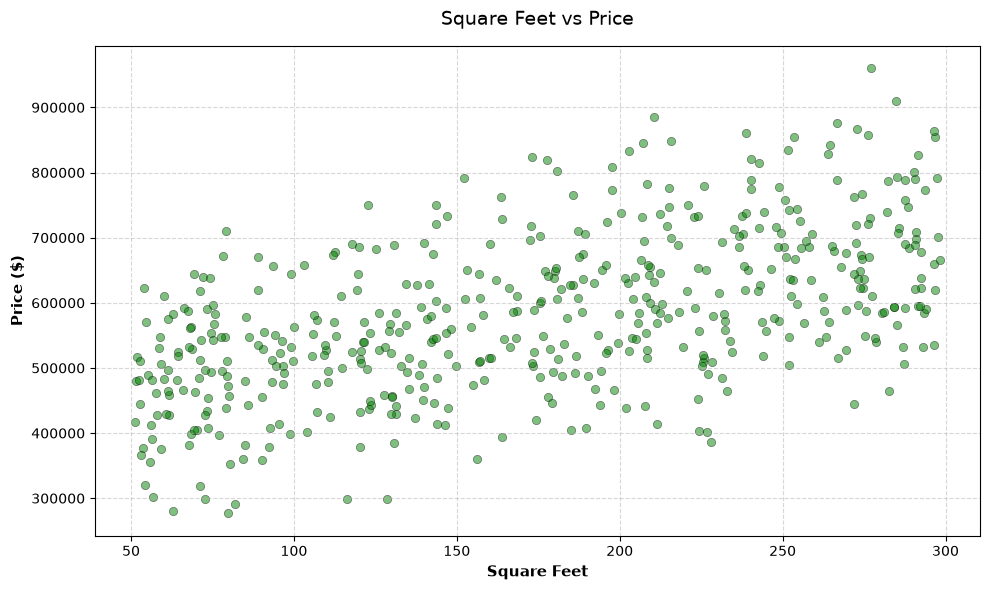

In [10]:
# Task 2.2. Visualise the relationship between Square Feet and Price using a scatter plot

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set the overall dimensions (width, height) of the figure canvas
plt.figure(figsize=(10, 6))

# Generate a scatter plot using Seaborn's direct DataFrame integration
sns.scatterplot(
    data=df_house_price,
    x="Square_Feet",
    y="Price",
    alpha=0.5,  # Transparency to handle overlapping points
    color="green",  # Color of the data markers
    edgecolors="k",  # Black border around markers for better contrast
)

# Customize the chart title and axis labels
plt.title("Square Feet vs Price", fontsize=14, pad=15)
plt.xlabel("Square Feet", fontsize=11, fontweight="bold")
plt.ylabel("Price ($)", fontsize=11, fontweight="bold")

# Add a subtle grid to make data reading easier
plt.grid(True, linestyle="--", alpha=0.5)

# Automatically adjust subplot parameters to fit the figure area cleanly
plt.tight_layout()

# Render and display the plot
plt.show()

Based on this scatter plot, here are the key insights about the relationship between Square Feet and Price:

Positive Correlation: There is a clear upward trend. As the Square_Feet increases (moving right along the x-axis), the Price tends to increase as well (moving up along the y-axis). Larger homes generally cost more.   

Linear-ish Trend: The relationship looks fairly linear—it follows a general upward slope rather than a curve.   

Spread and Variance: While there is a clear trend, there is also a noticeable amount of scatter (spread) vertically. For example, a house around 200 square feet can range anywhere from roughly $400,000 to nearly $850,000. This tells you that square footage isn't the only factor driving price; other variables (like Location_Score or Num_Bedrooms) are likely influencing those price differences. 

    Here is a quick summary of what sns.pairplot(df_house_price) does:

    The Goal: It provides an instant, bird's-eye view of your entire dataset for Exploratory Data Analysis (EDA).

    The Output: A grid of multiple plots comparing every numerical column against every other numerical column in your DataFrame.

    Key Components:

    Off-Diagonal Plots (Scatter Plots): Show the relationship and correlation between pairs of different variables (e.g., how Price relates to Square Feet, Bedrooms, etc.).

    Diagonal Plots (Histograms/KDE): Show the distribution and spread of each single variable on its own.

    Why It's Useful: It saves you from writing dozens of individual plot commands, letting you spot trends, linear relationships, and data skews across your whole dataset with a single line of code.

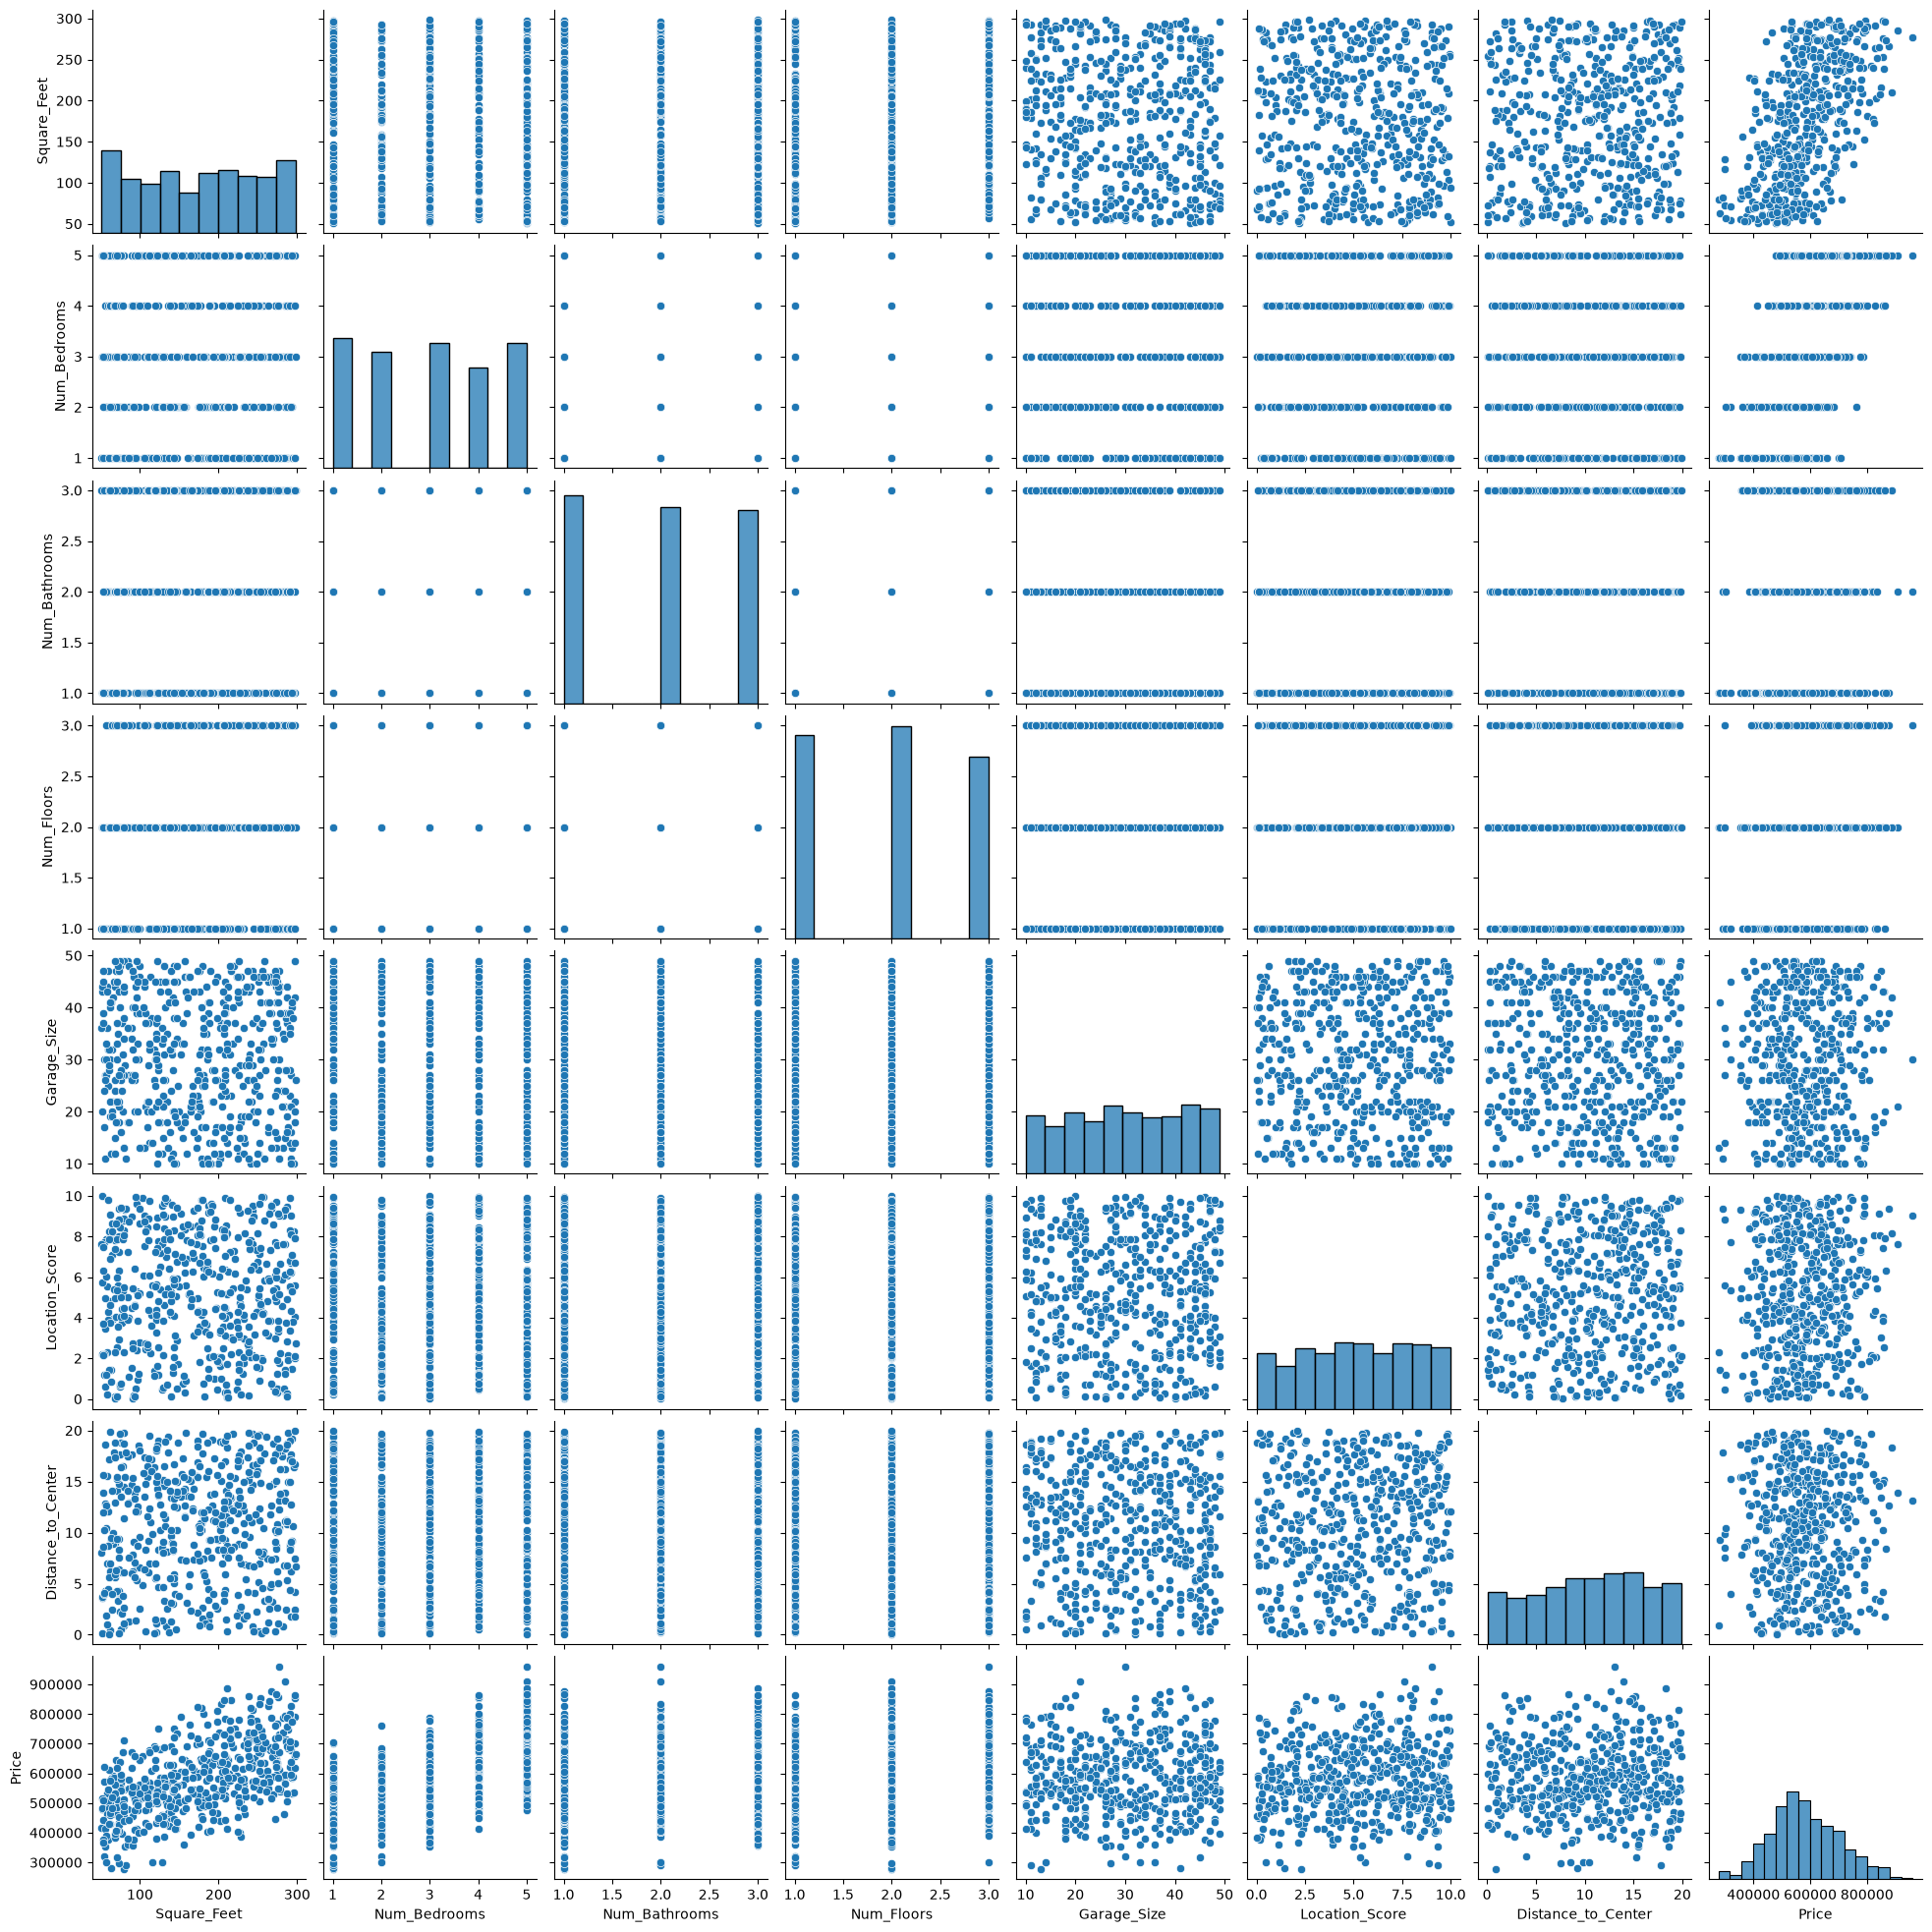

In [12]:
sns.pairplot(df_house_price)

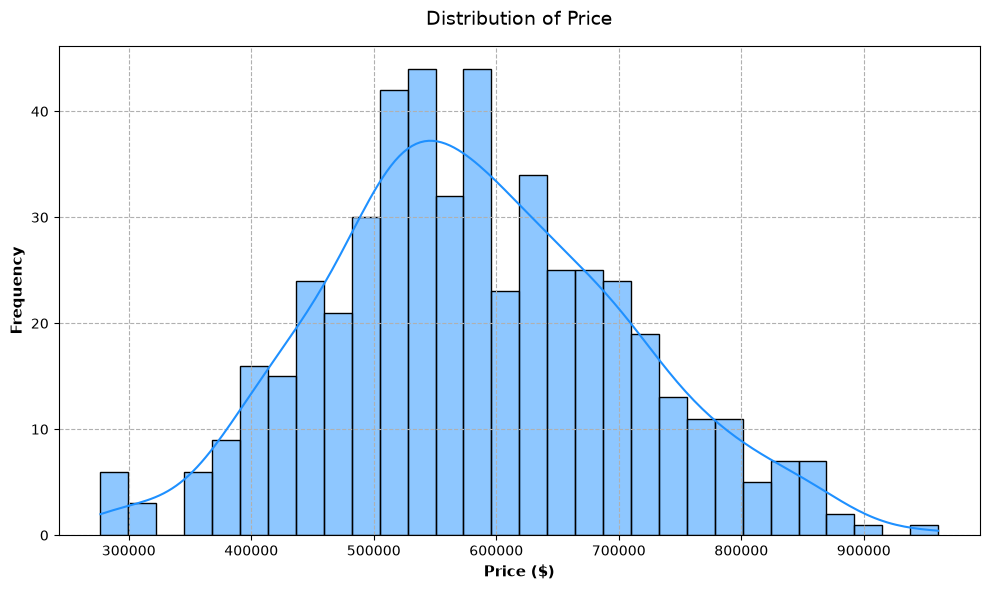

In [15]:
# Task 2.3. Visualise the distribution of the Price variable using a histogram

# Import required visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set the dimensions (width, height) of the figure canvas
plt.figure(figsize=(10, 6))

# Generate the histogram with a Kernel Density Estimate (KDE) curve
sns.histplot(
    df_house_price["Price"], bins=30, kde=True, color="dodgerblue", edgecolors="k"
)
# bins = Number of bins to divide the data into
# kde = Overlay a smooth probability density curve
# color = Color of the histogram bars
# edgecolors = Black borders around bars for crisp visual separation

plt.title("Distribution of Price", fontsize=14, pad=15)
plt.xlabel("Price ($)", fontsize=11, fontweight="bold")
plt.ylabel("Frequency", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--")

plt.tight_layout()
plt.show()

Task 2.5 Insight (Price Distribution): 

The histogram indicates that house prices are fairly evenly distributed around a central bell-like shape, suggesting a balanced dataset without extreme skewness.

                    Square_Feet  Num_Bedrooms  Num_Bathrooms  Num_Floors  \
Square_Feet            1.000000     -0.049918      -0.001667    0.056873   
Num_Bedrooms          -0.049918      1.000000      -0.056808    0.009088   
Num_Bathrooms         -0.001667     -0.056808       1.000000   -0.040895   
Num_Floors             0.056873      0.009088      -0.040895    1.000000   
Garage_Size           -0.051598     -0.065481       0.055707   -0.082763   
Location_Score        -0.035270     -0.000357      -0.013855    0.019928   
Distance_to_Center     0.093080      0.040511      -0.082571    0.035164   
Price                  0.558604      0.563973       0.156689    0.177435   

                    Garage_Size  Location_Score  Distance_to_Center     Price  
Square_Feet           -0.051598       -0.035270            0.093080  0.558604  
Num_Bedrooms          -0.065481       -0.000357            0.040511  0.563973  
Num_Bathrooms          0.055707       -0.013855           -0.082571  0.1566

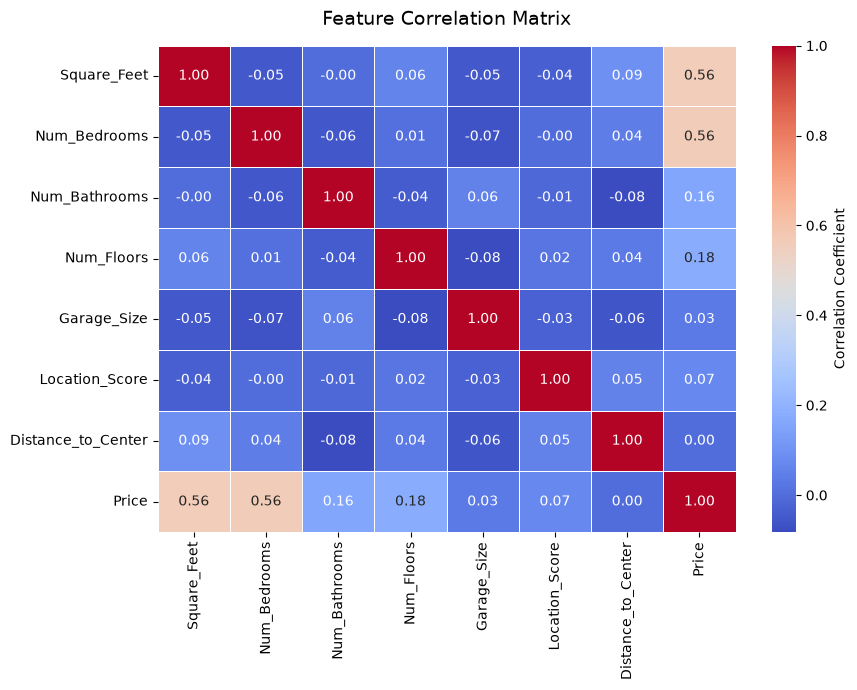

In [25]:
# Task 2.4: Compute correlation matrix
corr_matrix = df_house_price.corr()
print(corr_matrix)

# Visualise correlation matrix using a heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"label": "Correlation Coefficient"},
)
plt.title("Feature Correlation Matrix", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

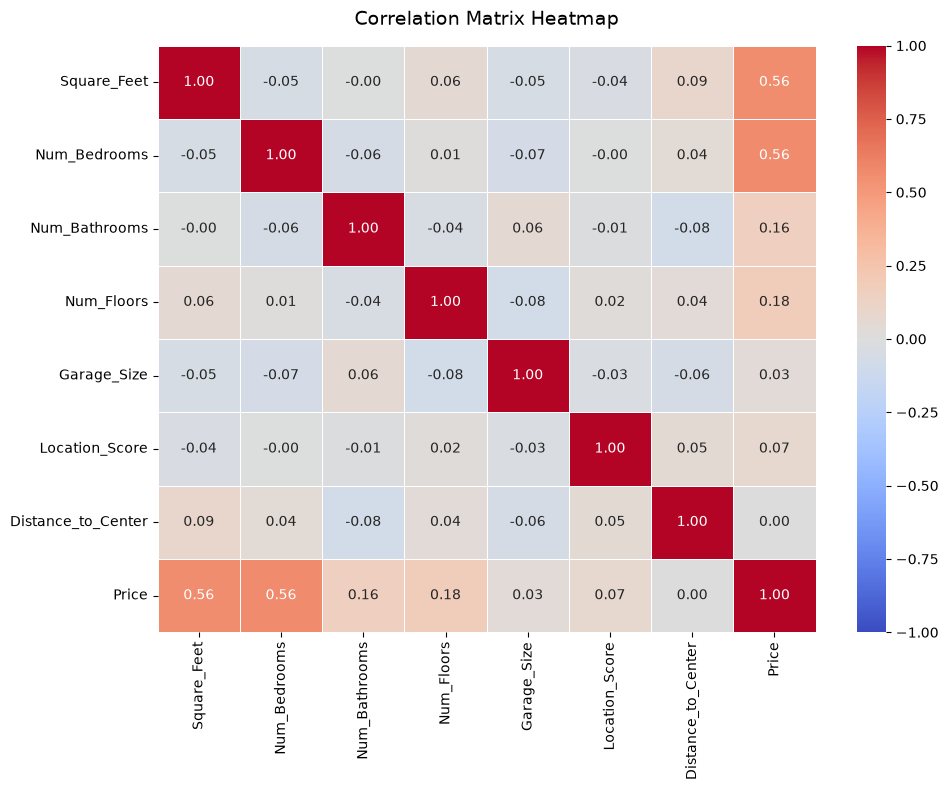

In [19]:
# Task 2.4. Compute and visualize the correlation matrix between the features

# Import required visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Compute the correlation matrix for all numerical columns in the dataframe
corr_matrix = df_house_price.corr()
# print(corr_matrix)

# Set up the figure canvas dimensions (width, height)
plt.figure(figsize=(10, 8))

# Generate the heatmap visualization
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1
)
# annot = Display the correlation values inside each cell
# cmap = Use a diverging color map (blue for negative, red for positive)
# fmt = Format the numbers to 2 decimal places
# linewidths = Add thin grid lines between cells for cleaner separation
# vmin, vmax = Fix the color scale bounds from -1 to 1 for consistency

# Customize the chart title and layout spacing
plt.title("Correlation Matrix Heatmap", fontsize=14, pad=15)
plt.tight_layout()

# Render and display the final heatmap plot
plt.show()

Task 2.5 Insight (Correlation Matrix): 

The heatmap highlights that Square_Feet has the strongest positive correlation with Price, making it the most influential predictor, whereas features like Distance_to_Center show a negative correlation.

Step 3. Creating a Multiple Linear Regression (MLR) Model


In this step, we will use Multiple Linear Regression to predict the Price of the house based on the features. We will split the data into a training set and a testing set, fit the model, and evaluate its performance.

Task 3.1. Split the Data into Features and Target Split the dataset into features (X) and target variable (y)

Task 3.2. Split the Data into Training and Testing Sets Split the data into training (80%) and testing (20%) sets

Task 3.3. Train the Multiple Linear Regression Model Train the Multiple Linear Regression (MLR) model using the training data

Task 3.4. Visualise the Predicted vs Actual Prices Create a scatter plot comparing the actual prices and predicted prices for the test set

Task 3.5. Evaluate the Model Evaluate the model using Root Mean Squared Error (RMSE) and interpret the results

Task 3.6. Write 1–2 sentences explaining the insights from the visualisation

In [20]:
# Task 3.1. Split the Data into Features and Target Split the dataset into features (X) and target variable (y)

# Select the features (inputs) the model will use to make predictions
# Drop 'Price', leaving every other columns as a feature in X
X = df_house_price.drop(columns=["Price"])

# Select the target variable (the answer/price we want the model to learn to predict)
y = df_house_price["Price"]

In [21]:
# Task 3.2. Split the Data into Training and Testing Sets Split the data into training (80%) and testing (20%) sets

# Import the function used to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Split data into training (80%) and testing (20%) sets for machine learning
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Print the shape/size of the train and test sets to verify
print(f"Training Data: {X_train.shape}, Testing Data: {X_test.shape}")

Training Data: (400, 7), Testing Data: (100, 7)


In [23]:
# 3.3. Train the Multiple Linear Regression Model Train the Multiple Linear Regression (MLR) model using the training data

from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
model_lr = LinearRegression()

# Train (fit) the model using the training data
model_lr.fit(X_train, y_train)

# Generate predictions on the testing dataset
y_pred_lr = model_lr.predict(X_test)

In [24]:
# Create a DataFrame to compare actual prices side-by-side with model predictions
results_df = pd.DataFrame({"Actual Price": y_test, "Predicted Price (MLR)": y_pred_lr})

# Print the comparison table
print(results_df)

     Actual Price  Predicted Price (MLR)
361   591058.7089          525669.926934
73    667693.0003          668141.051861
374   532377.5802          467168.904743
155   478489.2990          498375.548472
104   730197.4806          691359.973840
..            ...                    ...
347   464849.9178          493645.118779
86    572360.6499          643248.170875
75    557752.8374          454235.083741
438   649930.0523          564489.566281
15    523527.9747          456453.859956

[100 rows x 2 columns]


Close Predictions:

Row 347: Real price was 464,849, and MLR guessed 493,645 (a relatively close guess).

Bigger Misses:

Row 75: Real price was 557,752, but MLR guessed 454,235 (underestimating by over 100,000).

Row 86: Real price was 572,360, but MLR guessed 643,248 (overestimating by about 70,000).

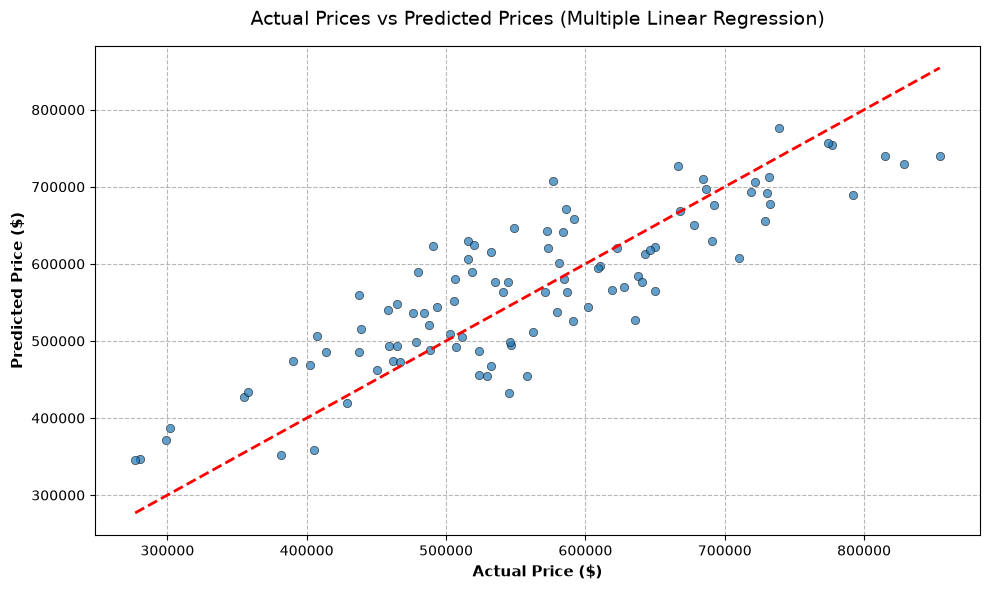

In [26]:
# Task 3.4. Visualise the Predicted vs Actual Prices Create a scatter plot comparing the actual prices and
# predicted prices for the test set

import matplotlib.pyplot as plt  # Imports the core plotting library
import seaborn as sns  # Imports Seaborn for enhanced visualizations

# Set the size of the graph figure (8 inches wide by 6 inches tall)
plt.figure(figsize=(10, 6))

# Create a scatter plot showing Actual Prices vs Predicted Prices
sns.scatterplot(
    data=results_df,
    x="Actual Price",
    y="Predicted Price (MLR)",
    alpha=0.7,
    edgecolors="k",
)

# Draw a red dashed diagonal line (where predictions perfectly match actuals) for reference
plt.plot(
    [results_df["Actual Price"].min(), results_df["Actual Price"].max()],
    [results_df["Actual Price"].min(), results_df["Actual Price"].max()],
    color="red",
    linestyle="--",
    lw=2,
)

# Add a soft gray, dashed background grid to make the chart easier to read
plt.grid(axis="both", linestyle="--", alpha=0.6, color="#888888")

# Add labels for the axes and a title to the chart
plt.xlabel("Actual Price ($)", fontsize=11, fontweight="bold")
plt.ylabel("Predicted Price ($)", fontsize=11, fontweight="bold")
plt.title(
    "Actual Prices vs Predicted Prices (Multiple Linear Regression)",
    fontsize=14,
    pad=15,
)

# Automatically adjust plot spacing so labels and titles don't get cut off
plt.tight_layout()

# Display the final plot
plt.show()

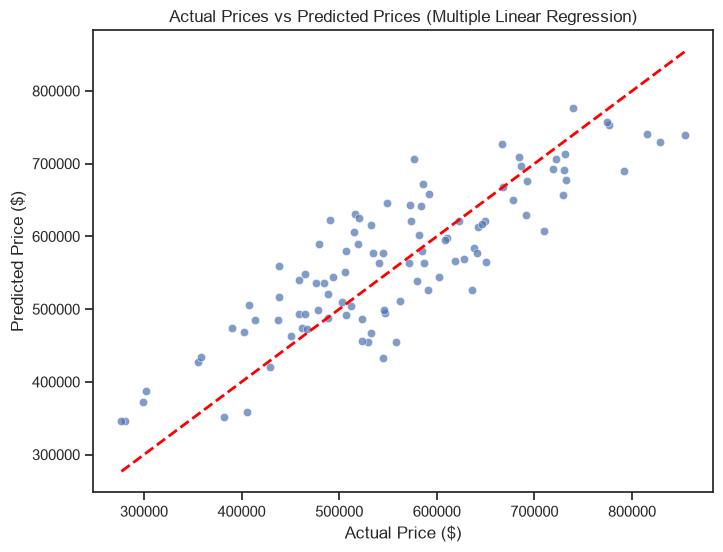

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=results_df, x="Actual Price", y="Predicted Price (MLR)", alpha=0.7)

plt.plot(
    [results_df["Actual Price"].min(), results_df["Actual Price"].max()],
    [results_df["Actual Price"].min(), results_df["Actual Price"].max()],
    color="red",
    linestyle="--",
    lw=2,
)

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual Prices vs Predicted Prices (Multiple Linear Regression)")
plt.show()

In [32]:
# Task 3.5. Evaluate the Model
# We evaluate model performance by calculating the Root Mean Squared Error(RMSE).

# Import NumPy for mathematical operations (like square root)
import numpy as np

# Import Mean Squared Error to measure how far off the model's predictions are
from sklearn.metrics import mean_squared_error

# Calculate Root Mean Squared Error (RMSE) to measure prediction accuracy (lower is better)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

# Print the final error score
print(f"Root Mean Squared Error (RMSE) for MLR: {rmse_lr}")

Root Mean Squared Error (RMSE) for MLR: 63952.37599755185


Result: RMSE = $63,952.38

Interpretation: On average, the model's price predictions deviate from the actual house sale prices by about $63,952.38. Lower RMSE values indicate better predictive accuracy.

Step 4. Compare with Random Forest Regressor


Task 4.1. Train a Random Forest Model Train a Random Forest Regressor model and evaluate its performance

Task 4.2: Visualise Actual vs Predicted Prices for Random Forest Create a scatter plot comparing the actual prices and predicted prices for the Random Forest model

Task 4.3: Model Comparison Compare the RMSE values of both the MLR and Random Forest models. Which model performs better?

In [33]:
# Task 4.1. Train a Random Forest Model Train a Random Forest Regressor model and evaluate its performance

from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(n_estimators=200, random_state=42)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

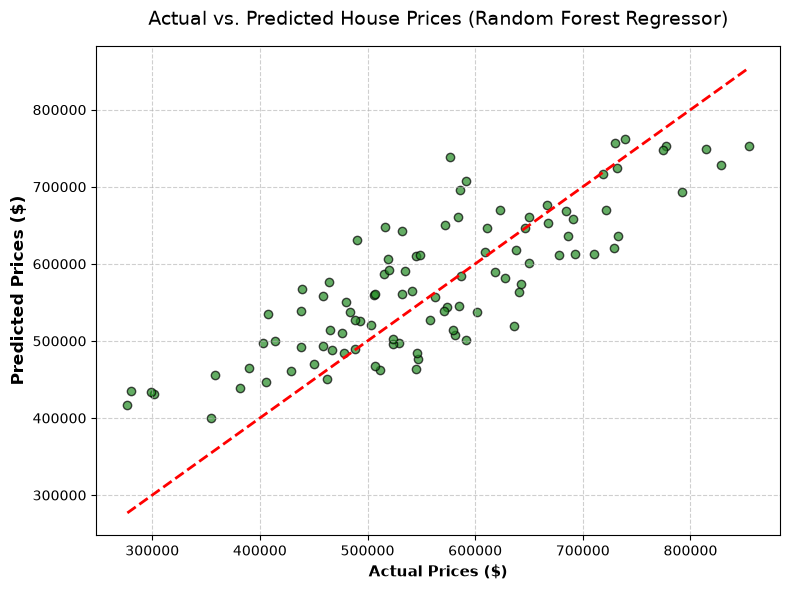

In [34]:
# Task 4.2: Visualise Actual vs Predicted Prices for Random Forest Create a scatter plot comparing
# the actual prices and predicted prices for the Random Forest model

import matplotlib.pyplot as plt

# Create a figure for the scatter plot
plt.figure(figsize=(8, 6))

# Plot actual vs. predicted test prices with green markers and black borders
plt.scatter(y_test, y_pred_rf, color="forestgreen", alpha=0.7, edgecolors="k")

# Add a 45-degree reference line (y = x) representing ideal predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    lw=2,
    label="Ideal Fit (y = x)",
)

# Style axis labels, title, and grid for readability
plt.xlabel("Actual Prices ($)", fontsize=11, fontweight="bold")
plt.ylabel("Predicted Prices ($)", fontsize=12, fontweight="bold")
plt.title(
    "Actual vs. Predicted House Prices (Random Forest Regressor)", fontsize=14, pad=15
)

plt.grid(True, linestyle="--", alpha=0.6)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [35]:
# Create a DataFrame to compare actual prices side-by-side with Random Forest predictions
results_df_rf = pd.DataFrame(
    {"Actual Price": y_test, "Predicted Price (Random Forest)": y_pred_rf}
)

print(results_df_rf.head())

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
print(f"Root Mean Squared Error (RMSE) for Random Forest: {rmse_rf}")

     Actual Price  Predicted Price (Random Forest)
361   591058.7089                    500917.205677
73    667693.0003                    652733.219915
374   532377.5802                    561417.212990
155   478489.2990                    484736.883594
104   730197.4806                    757194.708780
Root Mean Squared Error (RMSE) for Random Forest: 71998.81347025468


--------------------------------------------------------------
Display a Table with Actual vs Predicted Prices for all models

In [36]:
# Combine actual prices and both models' predictions into a single comparison table
results_df = pd.DataFrame(
    {
        "Actual Price": y_test,
        "Predicted Price (MLR)": y_pred_lr,
        "Predicted Price (Random Forest)": y_pred_rf,
    }
)

print(results_df.head())

     Actual Price  Predicted Price (MLR)  Predicted Price (Random Forest)
361   591058.7089          525669.926934                    500917.205677
73    667693.0003          668141.051861                    652733.219915
374   532377.5802          467168.904743                    561417.212990
155   478489.2990          498375.548472                    484736.883594
104   730197.4806          691359.973840                    757194.708780


In [37]:
# Task 4.3: Model Comparison Compare the RMSE values of both the MLR and Random Forest models. Which model performs better?

print(f"RMSE for MLR: {rmse_lr}")
print(f"RMSE for Random Forest: {rmse_rf}")

if rmse_lr < rmse_rf:
    print("The Multiple Linear Regression model performs better based on RMSE.")
else:
    print("The Random Forest model perfoms better based on RMSE.")

RMSE for MLR: 63952.37599755185
RMSE for Random Forest: 71998.81347025468
The Multiple Linear Regression model performs better based on RMSE.


Step 5: Conclusion and Insights
Task 5.1: Insights and Recommendations

Based on the RMSE and visualisations, summarise which model performs better and why.

Discuss any improvements that could be made to both models.

Final Model Comparison Summary

Multiple Linear Regression (MLR) RMSE = $63,952.38

Random Forest RMSE = $71,998.81

Conclusion:

The Multiple Linear Regression model performs better on this test set, achieving a lower Root Mean Squared Error than the Random Forest model. This indicates that the relationships on the housing dataset lean more heavily toward linear patterns, which the simpler linear model captures cleanly without the higher variance seen in the default tree ensemble.